**Table of contents**<a id='toc0_'></a>    
- [Course 1: Financial Markets, Insurance, CAPM](#toc1_)    
  - [Lesson 3: Insurance](#toc1_1_)    
    - [An Alternative to Insurance: Portfolio Management](#toc1_1_1_)    
  - [Lesson 4](#toc1_2_)    
    - [Portfolio Diversification](#toc1_2_1_)    
    - [Salon - Risk](#toc1_2_2_)    
    - [CAPM](#toc1_2_3_)    
    - [CAPM and Diversification](#toc1_2_4_)    
    - [Short Sales](#toc1_2_5_)    
    - [Calculating the Optimal Portfolio](#toc1_2_6_)    
    - [Efficient Portfolio Frontier](#toc1_2_7_)    
    - [Chalk Talk - Gordon Growth Model](#toc1_2_8_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# <a id='toc1_'></a>[Course 1: Financial Markets, Insurance, CAPM](#toc0_)

## <a id='toc1_1_'></a>[Lesson 3: Insurance](#toc0_)

- 1660s: first life tables
  - showing $\mathbb{P}(\text{dying})$ at each age
- 1694: 1st health insurance
- 1840: highly-paid insurance salesmans
- 1850: 1st US health insurance
- 1880s: large cash value
- 1911: Unemployment insurance started in UK
- 1945: The McCarran-Ferguson Act of 1945 delegated insurance regulation to the states.
- Health Maintenance Act of 1973
  - Before doctors received money when people were sick, and thus they were not incentivized to cure people.
- ObamaCare:
  - fine for individuals who are not insured
  - fine for companies who don't provide insurance

Before 9/11/2001, insurers:
- Generally did not exclude terrorism risk, which they then saw as inconsequential. 
- TRIA

Insurance is not regulated by the federal government but by the state government (in the US).

### <a id='toc1_1_1_'></a>[An Alternative to Insurance: Portfolio Management](#toc0_)

- Diversification of ownership 
- Risk is inherent to investing
- "If it weren't risky, it wouldn't give you an extra return!"
- <span style="color:blue">Don't put all eggs in one basket</span>

## <a id='toc1_2_'></a>[Lesson 4](#toc0_)
### <a id='toc1_2_1_'></a>[Portfolio Diversification](#toc0_)

- All that should matter to an investor is the performance of the entire portfolio
- $\mu$ and $\sigma^2$ of the return of the whole portfolio matter
- Law of large numbers means that spreading over many independent assets reduces risk, has no effect on expected return.

We should care about how uncertain the return of the **whole** portfolio is.

- Ask: How does each asset contribute to my overall portfolio $\mathbb{V}$ and expected return?

### <a id='toc1_2_2_'></a>[Salon - Risk](#toc0_)

- hedge funds $=$ investment companies that are not approved for the general retail market
- so they are not allowed to advertise
- <span style="color:brown">systemic risk</span> = risk that the whole house collapses
- <span style="color:blue">If you help people manage risk, they will take more risk.</span> That's what we want
  - We want people, in their decisions about their education, to do some risk-taking.
  - Develop some specialty that is at risk of being obsolete
- **Let's encourage people to take chances!**

### <a id='toc1_2_3_'></a>[CAPM](#toc0_)

> $=$ <span style="color:brown">Capital Asset Pricing Model</span>

- asserts that all investors hold their optimal portfolio
- Consequence of the <span style="color:brown">Mututal Fund Theorem</span>: All investors hold the same portfolio of risky assets, the tangency portfolio
- Thus, CAPM says: tangency portfolio $=$ market portfolio
- implies taht the *expected return on the $i$-th asset* $=$ $\beta_i$
- Investment companies as providers of diversification
  - people needed mutual (/investment) funds (especially index funds)
- CAPM says: you wanna hold all types of assets of the risk pyramid
  - speculative: options, arts, gems, commodities, venture capitals, ...
  - high risk: investment real estate & REITs, international stocks and bonds, small company stocks, ...
  - moderate risk: Utility stocks, growth & income funds, blue chip stocks, S&P index funds, balanced funds, ...
  - low-moderate risk: US government agency securities, zero coupon bonds, corporate bonds
  - low risk: savings accounts, money market accounts, municipal bonds, government notes & bonds

We can plot the return of the market $r_{market}$ against the return of an individual stock, e.g. Nvidia, $r_{nvda}$.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- 1. Create Dummy Data (Replace this with your actual data) ---
# You'll need a DataFrame where each row represents a year,
# and you have columns for 'Market_Return' and 'Stock_Return'.
# Returns should be in percentage (e.g., 10 for 10%, -5 for -5%).

data = {
    'Year': [2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024],
    'Market_Return': [13.4, 32.4, 13.7, 1.2, 11.9, 21.8, -4.4, 31.5, 18.4, 28.7, -18.1, 26.3, 10.0], # Example S&P 500 annual returns
    'Stock_Return': [15.0, 45.0, 20.0, -5.0, 25.0, 35.0, -10.0, 50.0, 80.0, 120.0, -25.0, 60.0, 20.0]  # Example NVDA annual returns
}
df_returns = pd.DataFrame(data)

# Set 'Year' as the index for easier visualization if desired, though not strictly necessary for scatter plot
df_returns.set_index('Year', inplace=True)

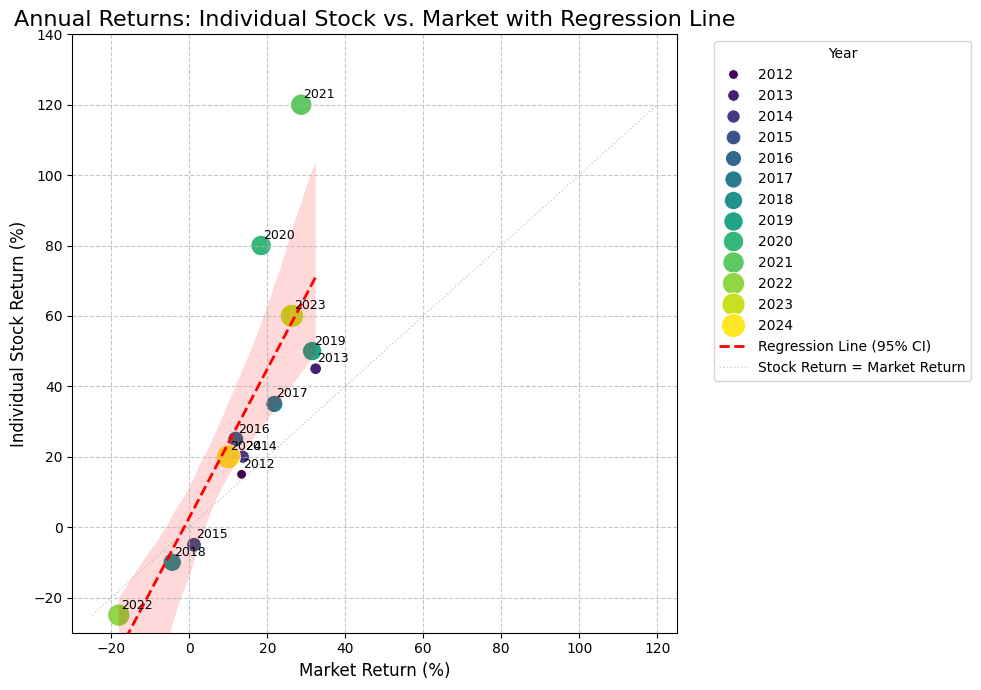

In [4]:
# --- 2. Create the Scatter Plot with Regression Line ---

plt.figure(figsize=(10, 7)) # Set the figure size

# Plot the scatter points
sns.scatterplot(
    data=df_returns,
    x='Market_Return',
    y='Stock_Return',
    hue='Year', # Color points by year
    size='Year', # Size points by year (can highlight progression)
    sizes=(50, 300), # Range of sizes for points
    palette='viridis', # Color palette
    legend='full' # Show full legend for hue and size
)

# Add the regression line
sns.regplot(
    data=df_returns,
    x='Market_Return',
    y='Stock_Return',
    color='red', # Color of the regression line
    scatter=False, # Do not plot scatter points again
    ci=95, # Confidence interval for the regression estimate (e.g., 95%)
    line_kws={'linestyle': '--', 'linewidth': 2}, # Line style for regression line
    label='Regression Line (95% CI)' # Label for legend
)


# Add annotations for each year
for i, row in df_returns.iterrows():
    plt.text(row['Market_Return'] + 0.5, row['Stock_Return'] + 1, str(i), fontsize=9, ha='left', va='bottom')

# --- 3. Add Labels and Title ---
plt.title('Annual Returns: Individual Stock vs. Market with Regression Line', fontsize=16)
plt.xlabel('Market Return (%)', fontsize=12)
plt.ylabel('Individual Stock Return (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Add a diagonal line (y=x) for reference: where stock return equals market return
max_return = max(df_returns['Market_Return'].max(), df_returns['Stock_Return'].max())
min_return = min(df_returns['Market_Return'].min(), df_returns['Stock_Return'].min())
plt.plot([min_return, max_return], [min_return, max_return], color='darkgray', linestyle=':', linewidth=1, alpha=0.6, label='Stock Return = Market Return')

# Adjust plot limits if necessary to ensure all points and labels are visible
plt.xlim(min_return - 5, max_return + 5)
plt.ylim(min_return - 5, max_return + 20) # Adjust ylim to give space for labels if needed

# Adjust legend to include the regression line label
handles, labels = plt.gca().get_legend_handles_labels()
# Filter out duplicate labels/handles if they appeared from scatterplot and regplot automatically
unique_labels = dict(zip(labels, handles))
plt.legend(unique_labels.values(), unique_labels.keys(), title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout() # Adjust layout to prevent labels from overlapping

# --- 4. Display the Plot ---
plt.show()

- High $\beta$ stock $\Rightarrow$ stock is reacting more strongly to the market
- Negative $\beta$ stock $\Rightarrow$ when the economy is doing well, the asset is doing bad, when the economy is doing bad, the asset is doing well
- <span style="color:brown">idiosyncratic risk</span> $=$ the residuals $=$ the difference to the whole market which is *only due to* the individual stock

> The theory of the capitalized pricing model is that investors care more about beta than they do about idiosyncratic risk. because all these companies idiosyncratic risks will average out and wont matter. What matters is the systematic risk. The risk that correlates with the market. Those things do not average out not matter how many stocks you put in your portfolio.

Note the following about $\beta$: 
- $\beta = 1$: Moves with market's magnitude
- $\beta > 1$: Amplifies market movements (more volatile)
- $\beta < 1$: Dampens market movements (less volatile)
- $\beta = 0$: Independent of market movements
- $\beta < 0$: Moves opposite of market movements

The key is that **Beta** ($\beta$) <span style="color:blue">measures a stock's *relative volatility* (how much it moves *when* the market moves) and it's *correlation* with the market</span>, not its *absolute return** over a period.

- Thus, the absolute return of a stock can be $\gg$ market, but still the $\beta$ is nearly $1$, because if the market moves up then the stock also moves up. Just the absolute return on the stock is much higher than on the market.

$\textbf{Capital Asset Pricing Model (CAPM)}:$

$$
    E(R_i) = R_f + \beta_i \times (E(R_m) - R_f) + \alpha_i
$$

- $E(R_i) = $ Expected return of the investment
- $R_f = $ Risk-free rate
- $\beta_i = $ Beta of the investment
- $E(R_m) = $ Expected return of the market
- $\alpha_i = $ Alpha (excess return). Outperformance.

$\alpha$ represents the excess return that a stock generates above and beyond what would be predicted by its beta and the market's return. 

- One also wants negative $\beta$ stocks in one's portfolio

### <a id='toc1_2_4_'></a>[CAPM and Diversification](#toc0_)

$$
    r_i = r_f + \beta_i ( r_{\text{market}} - r_f )
$$

- Formula assumes everyone holds an optimal portfolio

### <a id='toc1_2_5_'></a>[Short Sales](#toc0_)

> <span style="color:brown">**Short Sell**</span> $=$ holding **negative** quantities of a stock.

How can one own a *negative* quantity of a stock? 

- You borrow the shares and sell them
- Now you owe the share to someone else

> Brokers can enable you to hold a negative quantity of a tradable asset: they borrow the security and sell it, escrow the proceeds, you receive the proceeds, owe the security

### <a id='toc1_2_6_'></a>[Calculating the Optimal Portfolio](#toc0_)

- We want $Cov < 0$, because assets move opposite from each other
- If $Cov > 0$, assets move in tandem with each other

### <a id='toc1_2_7_'></a>[Efficient Portfolio Frontier](#toc0_)

- Expresses the $\sigma$ (standard deviation) of the portfolio in terms of $r$

<p align="center">
  <img width="600" height="400" src="imgs/01_module/m1l4-efficient-portfolio-frontier.png">
</p>

- Business involves
    1. intuitive judgement
    2. risk taking

### <a id='toc1_2_8_'></a>[Chalk Talk - Gordon Growth Model](#toc0_)

$$
\begin{align*}
    PV &= \frac{x}{r - g} \\
       &= \frac{x}{1 + r} + \frac{x(1 + g)}{(1 + r^2)} + \frac{x(1 + g)^2}{(1 + r)^3} + \dots
\end{align*}
$$

- $PV = $ Present value
- $r = $ rate of discount
- $g = $ growth rate (given)